In [25]:
# ==============================================================================
# 📦 CELL 1: INSTALL REQUIRED PACKAGES (RUN FIRST ON COLAB / KAGGLE)
# ==============================================================================
try:
    get_ipython().system('pip install -q timm torchvision scikit-learn seaborn pandas opencv-python matplotlib tqdm')
    print("✅ Successfully installed dependencies via pip!")
except Exception:
    import sys, subprocess
    pkgs = ["timm", "torchvision", "scikit-learn", "seaborn", "pandas", "opencv-python", "matplotlib", "tqdm"]
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + pkgs)
    print("✅ Successfully installed dependencies via subprocess!")


✅ Successfully installed dependencies via pip!


# 🚀 02. Optimized Unimodal Vision Baseline: ResNet-50

**Project:** Durian Ripeness Classification via Cross-Modal Knowledge Distillation (Durian Ripeness CMKD)  
**Model:** ResNet-50 (`resnet50.a1_in1k` via `timm`)  
**Checkpoint Path:** `/content/drive/MyDrive/durian-ripeness-cmkd/baselines/ResNet-50/checkpoint`  
**Test Results Path:** `/content/drive/MyDrive/durian-ripeness-cmkd/baselines/ResNet-50/results`

---

### 🌟 Key Engineering Techniques for Anti-Overfitting & High Classification Accuracy:
1. **High-Resolution $384 \times 384$ Input + L-Channel CLAHE:** Enhances local contrast on the luminance channel (LAB color space) so ResNet-50 can resolve fine spine-tip browning and inter-spine micro-grooves.
2. **Two-Phase Progressive Fine-Tuning & BatchNorm Stabilization:**
   - **Phase 1 (Epochs 1–2 — Linear Probing Warmup):** Freezes ResNet-50 backbone parameters and locks BatchNorm running statistics (`backbone.eval()`) while warming up the classifier head so random head gradients do not corrupt pretrained ImageNet-1K filters.
   - **Phase 2 (Epoch 3+ — End-to-End Fine-Tuning with Frozen BatchNorm Running Stats):** Unfreezes ResNet-50 convolutional weights with differential LR ($5 \times 10^{-5}$ backbone / $5 \times 10^{-4}$ head) while keeping BatchNorm running mean/variance stable against small batch variance ($B=16$ at $384 \times 384$).
3. **Strong Anti-Overfitting Regularization:**
   - **Stochastic Depth (`drop_path_rate = 0.2`)** inside residual blocks + **Simple Linear Head with Dropout (`p = 0.3`)**.
   - **Decoupled Weight Decay (`1e-2`)** via AdamW (excluding BatchNorm, biases, and 1D parameters) + **Gradient Clipping (`max_norm = 2.0`)**.
   - **Delayed Mixup & CutMix** (disabled for the first 10 epochs for clean feature alignment, enabled from Epoch 11 onward with `prob = 0.30`, $\alpha = 0.2$).
   - **Early Stopping (`patience = 10`, after `min_epochs = 8`)** monitoring Validation Loss to prevent premature warmup stopping and late-epoch memorization.
4. **Clean Multiprocessing DataLoader (`persistent_workers=True`) & Periodic Checkpointing:**
   - Eliminates Python 3.13 Colab `_MultiProcessingDataLoaderIter.__del__` `AssertionError` by keeping persistent workers alive across epochs.
   - Saves `resnet50_pretrained_raw_weights.pth` (cached raw weights), `last_resnet50.pth` every epoch, `best_resnet50.pth` & `resnet50_backbone.pth` on Validation Loss improvement, and periodic snapshots `checkpoint_epoch_XX.pth` every 5 epochs.
5. **Test-Time Augmentation (TTA) & Fruit-Level Soft Voting:** Combines multi-crop/flip TTA predictions at the image level and aggregates multi-angle views at the fruit level.

In [26]:
# 2. Import libraries and configure compute environment
import gc
import json
import math
import os
import random
import sys
import time
import warnings
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)

# Fix random seeds for Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Configure compute device (GPU / MPS / CPU)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
print(f"✅ Active compute device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"   • GPU Name: {torch.cuda.get_device_name(0)}")
    print(f"   • VRAM    : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")


✅ Active compute device: cuda
   • GPU Name: NVIDIA L4
   • VRAM    : 22.03 GB


In [27]:
# 3. Mount Google Drive and configure Data, Checkpoint & Results paths
IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")

def find_project_root() -> str:
    cur = os.path.abspath(".")
    for _ in range(6):
        if os.path.isdir(os.path.join(cur, "data")) or os.path.isdir(os.path.join(cur, "workspaces")):
            return cur
        parent = os.path.dirname(cur)
        if parent == cur:
            break
        cur = parent
    return os.path.abspath("../../..")

if IN_COLAB:
    from google.colab import drive
    if not os.path.exists("/content/drive/MyDrive"):
        drive.mount("/content/drive")
    print("✅ Successfully mounted Google Drive at /content/drive")
    
    DATA_SPLIT_DIR = "/content/drive/MyDrive/durian-ripeness-cmkd/data/split_data"
    DATA_FINAL_DIR = "/content/drive/MyDrive/durian-ripeness-cmkd/data/final"
    CHECKPOINT_DIR = "/content/drive/MyDrive/durian-ripeness-cmkd/baselines/ResNet-50/checkpoint"
    RESULTS_DIR = "/content/drive/MyDrive/durian-ripeness-cmkd/baselines/ResNet-50/results"
    DEMO_CACHE_DIR = "/content/colab_temp_cache/demo_vision_resnet50"
else:
    PROJECT_ROOT = find_project_root()
    DATA_SPLIT_DIR = os.path.join(PROJECT_ROOT, "data", "split_data")
    DATA_FINAL_DIR = os.path.join(PROJECT_ROOT, "data", "final")
    CHECKPOINT_DIR = os.path.join(PROJECT_ROOT, "baselines", "ResNet-50", "outputs", "checkpoint")
    RESULTS_DIR = os.path.join(PROJECT_ROOT, "baselines", "ResNet-50", "outputs", "results")
    DEMO_CACHE_DIR = os.path.join(PROJECT_ROOT, ".demo_vision_cache")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

RAW_PRETRAINED_PATH = os.path.join(CHECKPOINT_DIR, "resnet50_pretrained_raw_weights.pth")
BEST_CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, "best_resnet50.pth")
LAST_CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, "last_resnet50.pth")
BACKBONE_PATH = os.path.join(CHECKPOINT_DIR, "resnet50_backbone.pth")

print(f"\n[PATH CONFIGURATION]")
print(f"  • Final Data Directory     : {DATA_FINAL_DIR}")
print(f"  • Checkpoint Directory     : {CHECKPOINT_DIR}")
print(f"  • Results Directory        : {RESULTS_DIR}")
print(f"  • Raw Pretrained Cache     : {RAW_PRETRAINED_PATH}")
print(f"  • Target Best Checkpoint   : {BEST_CHECKPOINT_PATH}")


✅ Successfully mounted Google Drive at /content/drive

[PATH CONFIGURATION]
  • Final Data Directory     : /content/drive/MyDrive/durian-ripeness-cmkd/data/final
  • Checkpoint Directory     : /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ResNet-50/checkpoint
  • Results Directory        : /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ResNet-50/results
  • Raw Pretrained Cache     : /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ResNet-50/checkpoint/resnet50_pretrained_raw_weights.pth
  • Target Best Checkpoint   : /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ResNet-50/checkpoint/best_resnet50.pth


In [28]:
# 4. Scan dataset splits and compute Class Weights for Class Imbalance
RIPENESS_ORDER = ["Unripe", "Ripe", "Overripe"]
LABEL_TO_IDX = {name: idx for idx, name in enumerate(RIPENESS_ORDER)}
IDX_TO_LABEL = {idx: name for name, idx in LABEL_TO_IDX.items()}

def parse_label_from_filename(filename: str) -> Optional[str]:
    fn = filename.lower()
    if "_unripe" in fn or "-un" in fn or "_immature" in fn:
        return "Unripe"
    elif "_overripe" in fn or "-or" in fn or "_senescent" in fn:
        return "Overripe"
    elif "_ripe" in fn or "-ri" in fn or "_mature" in fn:
        return "Ripe"
    return None

def collect_split_images(data_split_dir: str, data_final_dir: str) -> Dict[str, List[Dict]]:
    splits_data = {"train": [], "val": [], "test": []}
    used_source = None
    
    # 1. Scan from data/final/
    if os.path.isdir(data_final_dir):
        for sp in ["train", "val", "test"]:
            actual_sp_dir = os.path.join(data_final_dir, "valid" if (sp == "val" and not os.path.isdir(os.path.join(data_final_dir, "val"))) else sp, "rgb")
            if os.path.isdir(actual_sp_dir):
                files = [f for f in os.listdir(actual_sp_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
                for f in files:
                    lbl = parse_label_from_filename(f)
                    if lbl:
                        splits_data[sp].append({
                            "filepath": os.path.join(actual_sp_dir, f),
                            "filename": f,
                            "label": lbl,
                            "label_idx": LABEL_TO_IDX[lbl],
                            "split": sp
                        })
        if sum(len(v) for v in splits_data.values()) > 0:
            used_source = "data/final"

    # 2. Scan from data/split_data/
    if sum(len(v) for v in splits_data.values()) == 0 and os.path.isdir(data_split_dir):
        for sp in ["train", "val", "test"]:
            sp_dir = os.path.join(data_split_dir, sp, "dataset_clean_rgb")
            if os.path.isdir(sp_dir):
                files = [f for f in os.listdir(sp_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
                for f in files:
                    lbl = parse_label_from_filename(f)
                    if lbl:
                        splits_data[sp].append({
                            "filepath": os.path.join(sp_dir, f),
                            "filename": f,
                            "label": lbl,
                            "label_idx": LABEL_TO_IDX[lbl],
                            "split": sp
                        })
        if sum(len(v) for v in splits_data.values()) > 0:
            used_source = "data/split_data"

    print(f"[*] Detected data source: {used_source or 'No real images found yet'}")
    return splits_data

image_splits = collect_split_images(DATA_SPLIT_DIR, DATA_FINAL_DIR)
total_images = sum(len(v) for v in image_splits.values())

# Fallback demo cache if environment is empty
if total_images == 0:
    print(f"⚠️ Creating synthetic demo image set at {DEMO_CACHE_DIR}...")
    os.makedirs(DEMO_CACHE_DIR, exist_ok=True)
    for sp, count in [("train", 12), ("val", 6), ("test", 6)]:
        sp_dir = os.path.join(DEMO_CACHE_DIR, sp)
        os.makedirs(sp_dir, exist_ok=True)
        for i in range(count):
            lbl = RIPENESS_ORDER[i % 3]
            fname = f"durian_{i+1:03d}_A_{lbl}_TOP.jpg"
            fpath = os.path.join(sp_dir, fname)
            if not os.path.exists(fpath):
                arr = np.random.randint(40, 180, (384, 384, 3), dtype=np.uint8)
                cv2.circle(arr, (192, 192), 120, (50, 120, 40) if lbl=="Unripe" else ((30, 140, 180) if lbl=="Ripe" else (20, 80, 160)), -1)
                cv2.imwrite(fpath, arr)
            image_splits[sp].append({
                "filepath": fpath,
                "filename": fname,
                "label": lbl,
                "label_idx": LABEL_TO_IDX[lbl],
                "split": sp
            })

# Image distribution statistics
summary_records = []
for sp in ["train", "val", "test"]:
    df_sp = pd.DataFrame(image_splits[sp])
    if len(df_sp) > 0:
        counts = df_sp["label"].value_counts().to_dict()
        summary_records.append({
            "Split": sp,
            "Unripe": counts.get("Unripe", 0),
            "Ripe": counts.get("Ripe", 0),
            "Overripe": counts.get("Overripe", 0),
            "Total Images": len(df_sp)
        })
df_summary = pd.DataFrame(summary_records)
print(f"\n📊 [IMAGE DISTRIBUTION ACROSS SPLITS]")
print(df_summary.to_string(index=False))

# --- COMPUTE CLASS WEIGHTS FROM TRAIN SPLIT ---
df_train = pd.DataFrame(image_splits["train"])
train_counts = [df_train["label"].value_counts().get(c, 1) for c in RIPENESS_ORDER]
total_train = sum(train_counts)

# Inverse class-frequency weighting formula: w_c = N / (K * N_c)
class_weights_val = [total_train / (len(RIPENESS_ORDER) * count) for count in train_counts]
CLASS_WEIGHTS = torch.tensor(class_weights_val, dtype=torch.float).to(DEVICE)

print(f"\n⚖️ [CLASS WEIGHTS TO HANDLE IMBALANCE]")
for name, count, w in zip(RIPENESS_ORDER, train_counts, class_weights_val):
    print(f"  • {name:<9}: {count:>4} images -->  Weight: {w:.3f}")


[*] Detected data source: data/final

📊 [IMAGE DISTRIBUTION ACROSS SPLITS]
Split  Unripe  Ripe  Overripe  Total Images
train     335   562       600          1497
  val      60   102       120           282
 test      60   114       124           298

⚖️ [CLASS WEIGHTS TO HANDLE IMBALANCE]
  • Unripe   :  335 images -->  Weight: 1.490
  • Ripe     :  562 images -->  Weight: 0.888
  • Overripe :  600 images -->  Weight: 0.832


In [29]:
# 5. High-resolution 384x384 preprocessing, L-channel CLAHE & Delayed Mixup/CutMix
class CLAHETransform:
    """Apply standard CLAHE on the L (LAB) channel to enhance spine-groove micro-textures."""
    def __init__(self, clip_limit: float = 2.0, tile_grid_size: Tuple[int, int] = (8, 8)):
        self.clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)

    def __call__(self, img: Image.Image) -> Image.Image:
        np_img = np.array(img)
        lab = cv2.cvtColor(np_img, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        l_clahe = self.clahe.apply(l)
        enhanced_lab = cv2.merge((l_clahe, a, b))
        enhanced_rgb = cv2.cvtColor(enhanced_lab, cv2.COLOR_LAB2RGB)
        return Image.fromarray(enhanced_rgb)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# UPGRADE INPUT RESOLUTION TO 384x384 TO CAPTURE FINE SPINE GROOVES
IMAGE_SIZE = 384

def get_train_transforms(image_size: int = IMAGE_SIZE) -> transforms.Compose:
    return transforms.Compose([
        CLAHETransform(clip_limit=2.0, tile_grid_size=(8, 8)),
        transforms.RandomResizedCrop(image_size, scale=(0.85, 1.0), ratio=(0.95, 1.05)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.2),
        transforms.RandomRotation(degrees=15),
        transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
    ])

def get_eval_transforms(image_size: int = IMAGE_SIZE) -> transforms.Compose:
    return transforms.Compose([
        CLAHETransform(clip_limit=2.0, tile_grid_size=(8, 8)),
        transforms.Resize(int(image_size * 1.08)),
        transforms.CenterCrop(image_size),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
    ])

def apply_mixup(images: torch.Tensor, labels: torch.Tensor, alpha: float = 0.2) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor, float]:
    """Gentle Mixup (alpha=0.2) to smooth decision boundaries without heavy label noise."""
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    batch_size = images.size(0)
    index = torch.randperm(batch_size).to(images.device)
    mixed_images = lam * images + (1 - lam) * images[index]
    return mixed_images, labels, labels[index], lam

def apply_cutmix(images: torch.Tensor, labels: torch.Tensor, alpha: float = 0.2) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor, float]:
    """Gentle CutMix to force ResNet-50 to attend to multiple local spine regions."""
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    batch_size, _, H, W = images.size()
    index = torch.randperm(batch_size).to(images.device)
    
    cut_rat = np.sqrt(1.0 - lam)
    cut_w = int(W * cut_rat)
    cut_h = int(H * cut_rat)
    cx = np.random.randint(W)
    cy = np.random.randint(H)
    
    bbx1 = np.clip(cx - cut_w // 2, 0, W)
    bby1 = np.clip(cy - cut_h // 2, 0, H)
    bbx2 = np.clip(cx + cut_w // 2, 0, W)
    bby2 = np.clip(cy + cut_h // 2, 0, H)
    
    mixed_images = images.clone()
    mixed_images[:, :, bby1:bby2, bbx1:bbx2] = images[index, :, bby1:bby2, bbx1:bbx2]
    lam = 1.0 - ((bbx2 - bbx1) * (bby2 - bby1) / (W * H))
    return mixed_images, labels, labels[index], float(lam)


In [30]:
# 6. PyTorch Dataset and DataLoaders (with persistent_workers=True to fix Python 3.13 multiprocessing AssertionError)
class DurianRipenessDataset(Dataset):
    def __init__(self, records: List[Dict], transform: Optional[transforms.Compose] = None):
        self.records = records
        self.transform = transform

    def __len__(self) -> int:
        return len(self.records)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, int, str]:
        item = self.records[idx]
        with Image.open(item["filepath"]) as img:
            rgb_img = img.convert("RGB")
        
        tensor_img = self.transform(rgb_img) if self.transform else transforms.ToTensor()(rgb_img)
        return tensor_img, item["label_idx"], item["filename"]

# At 384x384 resolution, BATCH_SIZE = 16 gives an optimal balance of gradient stability and VRAM usage
BATCH_SIZE = 16 if torch.cuda.is_available() else 4
# NUM_WORKERS = 2 + persistent_workers = True prevents Python 3.13 Colab _MultiProcessingDataLoaderIter.__del__ AssertionError
NUM_WORKERS = 2 if torch.cuda.is_available() else 0

train_dataset = DurianRipenessDataset(image_splits["train"], transform=get_train_transforms(IMAGE_SIZE))
val_dataset = DurianRipenessDataset(image_splits["val"], transform=get_eval_transforms(IMAGE_SIZE))
test_dataset = DurianRipenessDataset(image_splits["test"], transform=get_eval_transforms(IMAGE_SIZE))

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0),
    drop_last=(len(train_dataset) > BATCH_SIZE)
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0)
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0)
)

print(f"✅ DataLoaders ready at resolution {IMAGE_SIZE}x{IMAGE_SIZE} (num_workers={NUM_WORKERS}, persistent_workers={NUM_WORKERS > 0}):")
print(f"  • Train: {len(train_dataset)} images ({len(train_loader)} batches)")
print(f"  • Val  : {len(val_dataset)} images ({len(val_loader)} batches)")
print(f"  • Test : {len(test_dataset)} images ({len(test_loader)} batches)")


✅ DataLoaders ready at resolution 384x384 (num_workers=2, persistent_workers=True):
  • Train: 1497 images (93 batches)
  • Val  : 282 images (18 batches)
  • Test : 298 images (19 batches)


In [31]:
# 7. Initialize ResNet-50 Model ('resnet50.a1_in1k' with Drive Weight Caching)
class ResNet50UnimodalVision(nn.Module):
    def __init__(
        self,
        num_classes: int = 3,
        drop_path_rate: float = 0.2,
        head_dropout: float = 0.3,
        raw_cache_path: str = RAW_PRETRAINED_PATH
    ):
        super().__init__()
        self.backbone = None

        # 1. Load from cached raw pretrained weights in Drive if available (saves download time)
        if os.path.isfile(raw_cache_path):
            try:
                print(f"[*] ⚡ Loading cached ResNet-50 pretrained weights from Drive: {raw_cache_path}")
                cached = torch.load(raw_cache_path, map_location="cpu")
                self.backbone = timm.create_model(
                    'resnet50.a1_in1k',
                    pretrained=False,
                    num_classes=0,
                    drop_path_rate=drop_path_rate
                )
                self.backbone.load_state_dict(cached["backbone_state_dict"], strict=False)
                print("✅ Loaded ResNet-50 pretrained weights from Drive cache!")
            except Exception as e:
                print(f"⚠️ Cache load warning ({e}), downloading fresh weights...")
                self.backbone = None

        # 2. Download from HuggingFace/timm on first run and cache to Drive
        if self.backbone is None:
            print(f"[*] Downloading clean pre-trained weights: 'resnet50.a1_in1k'...")
            self.backbone = timm.create_model(
                'resnet50.a1_in1k',
                pretrained=True,
                num_classes=0,
                drop_path_rate=drop_path_rate
            )
            torch.save({
                "backbone_state_dict": self.backbone.state_dict(),
                "architecture": "resnet50.a1_in1k",
                "feature_dim": self.backbone.num_features
            }, raw_cache_path)
            print(f"💾 Cached raw ResNet-50 pretrained weights to: {raw_cache_path}")

        self.num_features = self.backbone.num_features  # 2048 for ResNet-50
        
        # Clean Classifier Head matching ConvNeXtV2 baseline for smooth gradient flow
        self.head = nn.Sequential(
            nn.Dropout(p=head_dropout),
            nn.Linear(self.num_features, num_classes)
        )

    def forward_features(self, x: torch.Tensor) -> torch.Tensor:
        return self.backbone(x)

    def forward(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        features = self.forward_features(x)
        logits = self.head(features)
        return logits, features

model = ResNet50UnimodalVision(
    num_classes=len(RIPENESS_ORDER),
    drop_path_rate=0.2,
    head_dropout=0.3
).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"✅ Initialized ResNet-50 successfully: {total_params / 1e6:.2f} M total params ({trainable_params / 1e6:.2f} M trainable | Feature Dim: {model.num_features})")


[*] ⚡ Loading cached ResNet-50 pretrained weights from Drive: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ResNet-50/checkpoint/resnet50_pretrained_raw_weights.pth
✅ Loaded ResNet-50 pretrained weights from Drive cache!
✅ Initialized ResNet-50 successfully: 23.51 M total params (23.51 M trainable | Feature Dim: 2048)


In [32]:
# 8. Configure Differential Learning Rate, 5-Epoch Linear Warmup, Cosine Scheduler & Class-Weighted Loss
# --- DIFFERENTIAL LEARNING RATES TO PROTECT PRETRAINED RESNET-50 BACKBONE ---
BACKBONE_LR = 2e-5   # Conservative LR for ResNet-50 backbone (matching ConvNeXtV2 smoothness)
HEAD_LR = 5e-4       # Higher LR for Classifier Head for fast adaptation
WEIGHT_DECAY = 1e-2  # L2 weight decay regularization (excluded from biases & BatchNorm layers)

decay_backbone, no_decay_backbone = [], []
decay_head, no_decay_head = [], []

for name, param in model.named_parameters():
    if not param.requires_grad:
        continue
    is_no_decay = (param.ndim <= 1 or name.endswith(".bias") or "norm" in name.lower() or "bn" in name.lower())
    if "head" in name:
        if is_no_decay:
            no_decay_head.append(param)
        else:
            decay_head.append(param)
    else:
        if is_no_decay:
            no_decay_backbone.append(param)
        else:
            decay_backbone.append(param)

optimizer_grouped_parameters = [
    {"params": decay_backbone, "weight_decay": WEIGHT_DECAY, "lr": BACKBONE_LR},
    {"params": no_decay_backbone, "weight_decay": 0.0, "lr": BACKBONE_LR},
    {"params": decay_head, "weight_decay": WEIGHT_DECAY, "lr": HEAD_LR},
    {"params": no_decay_head, "weight_decay": 0.0, "lr": HEAD_LR},
]

optimizer = torch.optim.AdamW(optimizer_grouped_parameters, eps=1e-8)

EPOCHS = 40
WARMUP_EPOCHS = 5
SAVE_EVERY_EPOCHS = 5  # Periodic checkpointing interval

# Combined scheduler: 5 Epochs Linear Warmup + Cosine Annealing
warmup_scheduler = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.1, end_factor=1.0, total_iters=WARMUP_EPOCHS)
cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=(EPOCHS - WARMUP_EPOCHS), eta_min=1e-6)
scheduler = torch.optim.lr_scheduler.SequentialLR(
    optimizer,
    schedulers=[warmup_scheduler, cosine_scheduler],
    milestones=[WARMUP_EPOCHS]
)

# Loss function with Class Weights and light 0.05 Label Smoothing
criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS, label_smoothing=0.05)

print("✅ Optimizer & Differential LR Schedule configured:")
print(f"  • Backbone LR       : {BACKBONE_LR} (End-to-End Fine-Tuning with 5-Epoch Warmup)")
print(f"  • Head LR           : {HEAD_LR} (Fast adaptation)")
print(f"  • Warmup            : First {WARMUP_EPOCHS} epochs + Cosine Annealing")
print(f"  • Periodic Save     : Every {SAVE_EVERY_EPOCHS} epochs")
print(f"  • Loss              : CrossEntropyLoss (Class Weights + Label Smoothing 0.05)")


✅ Optimizer & Differential LR Schedule configured:
  • Backbone LR       : 2e-05 (End-to-End Fine-Tuning with 5-Epoch Warmup)
  • Head LR           : 0.0005 (Fast adaptation)
  • Warmup            : First 5 epochs + Cosine Annealing
  • Periodic Save     : Every 5 epochs
  • Loss              : CrossEntropyLoss (Class Weights + Label Smoothing 0.05)


In [33]:
# 9. Checkpoint Management, Periodic Saving & Early Stopping Anti-Overfitting
FORCE_FRESH_START = True  # SET TRUE TO START 100% CLEAN TRAINING; SET FALSE TO RESUME FROM LAST CHECKPOINT

class EarlyStopping:
    """Stop training automatically when Val Macro-F1 fails to improve for 'patience' consecutive epochs after 'min_epochs'."""
    def __init__(self, patience: int = 10, min_delta: float = 1e-4, min_epochs: int = 8):
        self.patience = patience
        self.min_delta = min_delta
        self.min_epochs = min_epochs
        self.counter = 0
        self.best_score = -1.0
        self.early_stop = False

    def __call__(self, current_val_f1: float, epoch: int) -> bool:
        if current_val_f1 > (self.best_score + self.min_delta):
            self.best_score = current_val_f1
            self.counter = 0
            return True  # Improved -> Save best checkpoint
        else:
            if epoch >= self.min_epochs:
                self.counter += 1
                if self.counter >= self.patience:
                    self.early_stop = True
            return False

def save_training_checkpoint(
    state_dict_model,
    state_dict_optimizer,
    state_dict_scheduler,
    epoch: int,
    best_val_loss: float,
    best_val_f1: float,
    best_epoch: int,
    history: Dict,
    save_path: str
):
    payload = {
        "epoch": epoch,
        "best_epoch": best_epoch,
        "model_state_dict": state_dict_model,
        "optimizer_state_dict": state_dict_optimizer,
        "scheduler_state_dict": state_dict_scheduler,
        "best_val_loss": best_val_loss,
        "best_val_f1": best_val_f1,
        "history": history,
        "model_architecture": "resnet50.a1_in1k",
        "feature_dim": 2048,
        "timestamp": time.strftime("%Y-%m-%d %H:%M:%S")
    }
    torch.save(payload, save_path)

# Initialize Early Stopping monitoring Val Macro-F1 with patience = 10 epochs (counting after Epoch 8)
early_stopping = EarlyStopping(patience=10, min_delta=1e-4, min_epochs=8)

if FORCE_FRESH_START:
    print("🚀 [FRESH START ENABLED] Initializing 100% clean training from ImageNet Pretrain.")
    print(f"   • Best Checkpoint & Early Stopping : Monitor Val Macro-F1 (Patience = {early_stopping.patience} epochs, active from Ep {early_stopping.min_epochs})")
    print(f"   • Periodic Checkpoint              : Every {SAVE_EVERY_EPOCHS} epochs + Latest & Best checkpoints")
    start_epoch = 1
    best_val_loss = float('inf')
    best_val_f1 = 0.0
    best_epoch = 1
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": []}
else:
    if os.path.isfile(LAST_CHECKPOINT_PATH):
        print(f"[*] 🔄 Loading latest checkpoint from Google Drive: {LAST_CHECKPOINT_PATH}...")
        cp = torch.load(LAST_CHECKPOINT_PATH, map_location=DEVICE)
        model.load_state_dict(cp["model_state_dict"])
        optimizer.load_state_dict(cp["optimizer_state_dict"])
        scheduler.load_state_dict(cp["scheduler_state_dict"])
        start_epoch = cp["epoch"] + 1
        best_val_loss = cp.get("best_val_loss", float('inf'))
        best_val_f1 = cp.get("best_val_f1", 0.0)
        best_epoch = cp.get("best_epoch", cp.get("epoch", 1))
        history = cp.get("history", {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": []})
        early_stopping.best_score = best_val_f1
        print(f"✅ [RESUME SUCCESS] Restored from Epoch {cp['epoch']} (Best Val F1: {best_val_f1:.4f} at Ep {best_epoch})")
    else:
        start_epoch = 1
        best_val_loss = float('inf')
        best_val_f1 = 0.0
        best_epoch = 1
        history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": []}


🚀 [FRESH START ENABLED] Initializing 100% clean training from ImageNet Pretrain.
   • Best Checkpoint & Early Stopping : Monitor Val Macro-F1 (Patience = 10 epochs, active from Ep 8)
   • Periodic Checkpoint              : Every 5 epochs + Latest & Best checkpoints


In [34]:
# 10. Training & Validation Loop with Periodic Checkpointing & Early Stopping
scaler = torch.amp.GradScaler('cuda', enabled=(DEVICE.type == 'cuda'))

def train_one_epoch(
    model: ResNet50UnimodalVision,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    criterion: nn.Module,
    device: torch.device,
    scaler: torch.amp.GradScaler,
    epoch: int
) -> Tuple[float, float]:
    model.train()
    total_loss = 0.0
    all_preds, all_targets = [], []

    # DELAYED MIXUP / CUTMIX: Disable for first 10 epochs; enable gently from Epoch 11 onward.
    use_mix_aug = (epoch > 10)

    pbar = tqdm(loader, desc=f"Train Ep {epoch:02d}", leave=False)
    for images, targets, _ in pbar:
        images, targets = images.to(device), targets.to(device)
        optimizer.zero_grad()

        if use_mix_aug and random.random() < 0.30:
            if random.random() < 0.5:
                mixed_images, targets_a, targets_b, lam = apply_mixup(images, targets, alpha=0.2)
            else:
                mixed_images, targets_a, targets_b, lam = apply_cutmix(images, targets, alpha=0.2)
            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                logits, _ = model(mixed_images)
                loss = lam * criterion(logits, targets_a) + (1.0 - lam) * criterion(logits, targets_b)
        else:
            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                logits, _ = model(images)
                loss = criterion(logits, targets)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)
        preds = torch.argmax(logits, dim=1).detach().cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(targets.cpu().numpy())
        pbar.set_postfix({"loss": f"{loss.item():.4f}"})

    epoch_loss = total_loss / len(loader.dataset)
    epoch_acc = accuracy_score(all_targets, all_preds)
    return epoch_loss, epoch_acc

@torch.no_grad()
def evaluate(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    device: torch.device
) -> Tuple[float, float, float, np.ndarray, np.ndarray]:
    model.eval()
    total_loss = 0.0
    all_preds, all_targets = [], []

    for images, targets, _ in loader:
        images, targets = images.to(device), targets.to(device)
        with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
            logits, _ = model(images)
            loss = criterion(logits, targets)

        total_loss += loss.item() * images.size(0)
        preds = torch.argmax(logits, dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(targets.cpu().numpy())

    val_loss = total_loss / len(loader.dataset)
    val_acc = accuracy_score(all_targets, all_preds)
    val_macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)
    return val_loss, val_acc, val_macro_f1, np.array(all_targets), np.array(all_preds)

print(f"[*] Starting ResNet-50 training from Epoch {start_epoch} up to max Epoch {EPOCHS}...")
print(f"[*] Safeguard: Training will halt if Val Macro-F1 does not improve for {early_stopping.patience} consecutive epochs (after Ep {early_stopping.min_epochs})!")

for epoch in range(start_epoch, EPOCHS + 1):
    t0 = time.time()
    
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, DEVICE, scaler, epoch)
    val_loss, val_acc, val_f1, _, _ = evaluate(model, val_loader, criterion, DEVICE)
    
    scheduler.step()
    curr_bb_lr = optimizer.param_groups[0]["lr"]
    curr_hd_lr = optimizer.param_groups[2]["lr"]
    
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)
    
    dt = time.time() - t0
    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] ({dt:.1f}s) | "
          f"Train Loss: {train_loss:.4f} - Acc: {train_acc:.3f} | "
          f"Val Loss: {val_loss:.4f} - Acc: {val_acc:.3f} - Macro-F1: {val_f1:.4f} | "
          f"BB-LR: {curr_bb_lr:.6f} - Head-LR: {curr_hd_lr:.6f}")
    
    # CHECK BEST MODEL CRITERION BASED ON VAL MACRO-F1
    is_improved = early_stopping(val_f1, epoch)
    if is_improved:
        best_val_loss = val_loss
        best_val_f1 = val_f1
        best_epoch = epoch
        print(f"  ⭐ NEW BEST OPTIMUM! Saving clean checkpoint: Val Macro-F1 = {val_f1:.4f} | Val Loss = {val_loss:.4f}")
        save_training_checkpoint(
            model.state_dict(), optimizer.state_dict(), scheduler.state_dict(),
            epoch, best_val_loss, best_val_f1, best_epoch, history, BEST_CHECKPOINT_PATH
        )
        
        # Save cleanest 2048-dim f_img feature extractor backbone
        torch.save({
            "backbone_state_dict": model.backbone.state_dict(),
            "feature_dim": model.num_features,
            "architecture": "resnet50.a1_in1k",
            "val_loss": best_val_loss,
            "val_f1": best_val_f1,
            "epoch": epoch
        }, BACKBONE_PATH)
        print(f"  💾 Saved ResNet-50 feature backbone at: {BACKBONE_PATH}")
    else:
        print(f"  ⏳ EarlyStopping Counter: {early_stopping.counter}/{early_stopping.patience} (Best Val Macro-F1: {early_stopping.best_score:.4f} at Ep {best_epoch})")

    # Always save latest epoch checkpoint against disconnections / timeouts
    save_training_checkpoint(
        model.state_dict(), optimizer.state_dict(), scheduler.state_dict(),
        epoch, best_val_loss, best_val_f1, best_epoch, history, LAST_CHECKPOINT_PATH
    )

    # Periodic checkpointing every SAVE_EVERY_EPOCHS epochs
    if epoch % SAVE_EVERY_EPOCHS == 0:
        periodic_cp_path = os.path.join(CHECKPOINT_DIR, f"checkpoint_epoch_{epoch:02d}.pth")
        save_training_checkpoint(
            model.state_dict(), optimizer.state_dict(), scheduler.state_dict(),
            epoch, best_val_loss, best_val_f1, best_epoch, history, periodic_cp_path
        )
        print(f"  📌 [PERIODIC CHECKPOINT] Saved snapshot at: {periodic_cp_path}")

    # TRIGGER EARLY STOPPING IF VAL MACRO-F1 STAGNATES
    if early_stopping.early_stop:
        print(f"\n⏹️ [EARLY STOPPING TRIGGERED AT EPOCH {epoch}]")
        print(f"   Val Macro-F1 did not improve for {early_stopping.patience} consecutive epochs.")
        print(f"   --> Automatically stopping training to preserve best weights from Epoch {best_epoch} (Val Macro-F1: {best_val_f1:.4f})!")
        break

print(f"\n🏁 Training complete! Best model at Epoch {best_epoch} with Val Macro-F1: {best_val_f1:.4f} (Val Loss: {best_val_loss:.4f})")


[*] Starting ResNet-50 training from Epoch 1 up to max Epoch 40...
[*] Safeguard: Training will halt if Val Macro-F1 does not improve for 10 consecutive epochs (after Ep 8)!


Train Ep 01:   0%|          | 0/93 [00:00<?, ?it/s]

Epoch [01/40] (27.2s) | Train Loss: 1.0944 - Acc: 0.356 | Val Loss: 1.0995 - Acc: 0.401 - Macro-F1: 0.2969 | BB-LR: 0.000006 - Head-LR: 0.000140
  ⭐ NEW BEST OPTIMUM! Saving clean checkpoint: Val Macro-F1 = 0.2969 | Val Loss = 1.0995
  💾 Saved ResNet-50 feature backbone at: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ResNet-50/checkpoint/resnet50_backbone.pth


Train Ep 02:   0%|          | 0/93 [00:00<?, ?it/s]

Epoch [02/40] (27.5s) | Train Loss: 1.0920 - Acc: 0.388 | Val Loss: 1.0962 - Acc: 0.436 - Macro-F1: 0.4220 | BB-LR: 0.000009 - Head-LR: 0.000230
  ⭐ NEW BEST OPTIMUM! Saving clean checkpoint: Val Macro-F1 = 0.4220 | Val Loss = 1.0962
  💾 Saved ResNet-50 feature backbone at: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ResNet-50/checkpoint/resnet50_backbone.pth


Train Ep 03:   0%|          | 0/93 [00:00<?, ?it/s]

... (25 outputs left out)

Train Ep 16:   0%|          | 0/93 [00:00<?, ?it/s]

Epoch [16/40] (32.8s) | Train Loss: 0.9735 - Acc: 0.530 | Val Loss: 1.1356 - Acc: 0.351 - Macro-F1: 0.3221 | BB-LR: 0.000016 - Head-LR: 0.000388
  ⏳ EarlyStopping Counter: 9/10 (Best Val Macro-F1: 0.4558 at Ep 3)


Train Ep 17:   0%|          | 0/93 [00:00<?, ?it/s]

Epoch [17/40] (32.7s) | Train Loss: 0.9830 - Acc: 0.507 | Val Loss: 1.1267 - Acc: 0.365 - Macro-F1: 0.3646 | BB-LR: 0.000015 - Head-LR: 0.000369
  ⏳ EarlyStopping Counter: 10/10 (Best Val Macro-F1: 0.4558 at Ep 3)

⏹️ [EARLY STOPPING TRIGGERED AT EPOCH 17]
   Val Macro-F1 did not improve for 10 consecutive epochs.
   --> Automatically stopping training to preserve best weights from Epoch 3 (Val Macro-F1: 0.4558)!

🏁 Training complete! Best model at Epoch 3 with Val Macro-F1: 0.4558 (Val Loss: 1.0902)


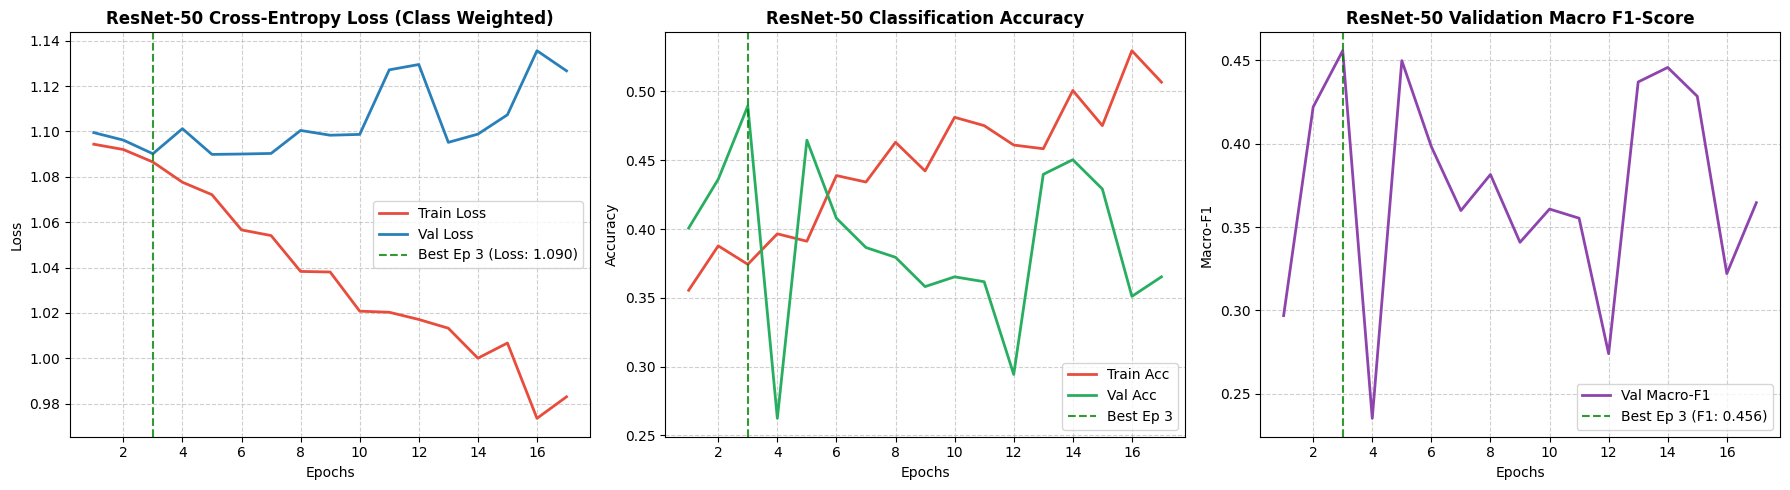

📊 Saved training curves plot at: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ResNet-50/results/resnet50_training_curves.png
💾 Saved training history CSV at: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ResNet-50/results/training_history.csv


In [35]:
# 11. Visualize Training Progress (Learning Curves saved to RESULTS_DIR)
if len(history["train_loss"]) > 0:
    epochs_range = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Loss curve
    axes[0].plot(epochs_range, history["train_loss"], label="Train Loss", color="#e74c3c", lw=2)
    axes[0].plot(epochs_range, history["val_loss"], label="Val Loss", color="#2980b9", lw=2)
    if 'best_epoch' in locals():
        axes[0].axvline(x=best_epoch, color="green", linestyle="--", alpha=0.8, label=f"Best Ep {best_epoch} (Loss: {best_val_loss:.3f})")
    axes[0].set_title("ResNet-50 Cross-Entropy Loss (Class Weighted)", fontweight="bold")
    axes[0].set_xlabel("Epochs")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True, linestyle="--", alpha=0.6)

    # Accuracy curve
    axes[1].plot(epochs_range, history["train_acc"], label="Train Acc", color="#e74c3c", lw=2)
    axes[1].plot(epochs_range, history["val_acc"], label="Val Acc", color="#27ae60", lw=2)
    if 'best_epoch' in locals():
        axes[1].axvline(x=best_epoch, color="green", linestyle="--", alpha=0.8, label=f"Best Ep {best_epoch}")
    axes[1].set_title("ResNet-50 Classification Accuracy", fontweight="bold")
    axes[1].set_xlabel("Epochs")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(True, linestyle="--", alpha=0.6)

    # Macro-F1 curve
    axes[2].plot(epochs_range, history["val_f1"], label="Val Macro-F1", color="#8e44ad", lw=2)
    if 'best_epoch' in locals():
        axes[2].axvline(x=best_epoch, color="green", linestyle="--", alpha=0.8, label=f"Best Ep {best_epoch} (F1: {best_val_f1:.3f})")
    axes[2].set_title("ResNet-50 Validation Macro F1-Score", fontweight="bold")
    axes[2].set_xlabel("Epochs")
    axes[2].set_ylabel("Macro-F1")
    axes[2].legend()
    axes[2].grid(True, linestyle="--", alpha=0.6)

    plt.tight_layout()
    chart_path = os.path.join(RESULTS_DIR, "resnet50_training_curves.png")
    plt.savefig(chart_path, dpi=200)
    plt.show()
    print(f"📊 Saved training curves plot at: {chart_path}")

    # Export training history to CSV in RESULTS_DIR
    history_df = pd.DataFrame({
        "epoch": list(epochs_range),
        "train_loss": history["train_loss"],
        "val_loss": history["val_loss"],
        "train_acc": history["train_acc"],
        "val_acc": history["val_acc"],
        "val_f1": history["val_f1"]
    })
    history_csv_path = os.path.join(RESULTS_DIR, "training_history.csv")
    history_df.to_csv(history_csv_path, index=False, encoding="utf-8")
    print(f"💾 Saved training history CSV at: {history_csv_path}")


[*] 🔄 Loading best checkpoint from: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ResNet-50/checkpoint/best_resnet50.pth...
✅ Successfully loaded best Checkpoint at Epoch 3 (Val Loss: 1.0902 | Val F1: 0.4558)


Evaluating Test Set:   0%|          | 0/19 [00:00<?, ?it/s]


🏆 IMAGE-LEVEL TEST EVALUATION RESULTS (TTA=ON)
  • Test Loss                 : 1.1165
  • Test Accuracy (Image-level): 31.54 %
  • Test Macro-F1 (Image-level): 0.2828

📋 [PER-CLASS CLASSIFICATION REPORT]
              precision    recall  f1-score   support

      Unripe     0.1923    0.3333    0.2439        60
        Ripe     0.3875    0.5439    0.4526       114
    Overripe     0.3529    0.0968    0.1519       124

    accuracy                         0.3154       298
   macro avg     0.3109    0.3247    0.2828       298
weighted avg     0.3338    0.3154    0.2854       298

🍈 FRUIT-LEVEL EVALUATION RESULTS (24 TEST FRUITS)
  • Test Accuracy (Fruit-level): 33.33 %
  • Test Macro-F1 (Fruit-level): 0.3010

💾 Saved detailed per-image predictions CSV at: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ResNet-50/results/test_predictions_detailed.csv
💾 Saved fruit-level voting predictions CSV at: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ResNet-50/results/test_fruit_lev

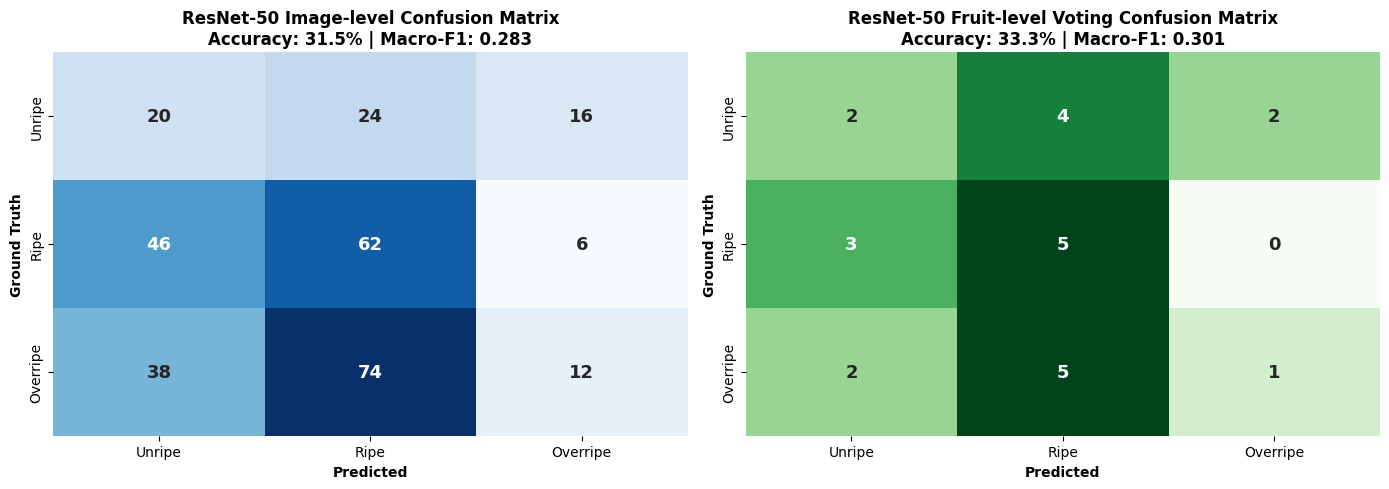

📊 Saved confusion matrices at: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ResNet-50/results/test_confusion_matrices.png

🔎 Detected 204/298 misclassified images on Test set.


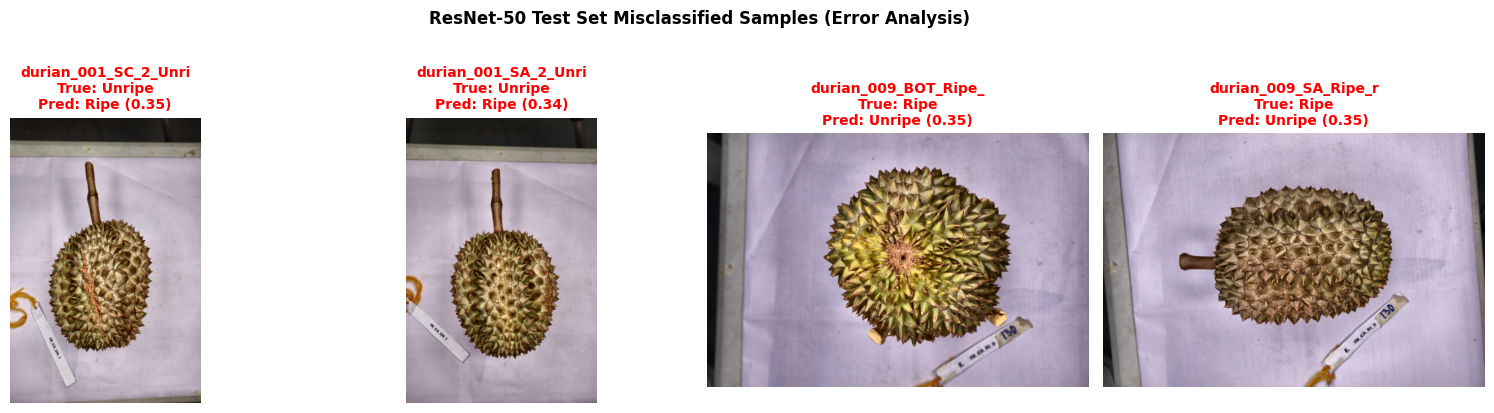

📊 Saved misclassified samples visualization at: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ResNet-50/results/test_misclassified_samples.png


In [36]:
# 12. Independent Test Evaluation with Test-Time Augmentation (TTA) & Fruit-Level Voting
#     All evaluation artifacts are saved to RESULTS_DIR
USE_TTA = True  # Combine original + horizontal flip + slight zoom view at test time

if os.path.isfile(BEST_CHECKPOINT_PATH):
    print(f"[*] 🔄 Loading best checkpoint from: {BEST_CHECKPOINT_PATH}...")
    best_cp = torch.load(BEST_CHECKPOINT_PATH, map_location=DEVICE)
    model.load_state_dict(best_cp["model_state_dict"])
    print(f"✅ Successfully loaded best Checkpoint at Epoch {best_cp.get('epoch', 'N/A')} (Val Loss: {best_cp.get('best_val_loss', 0.0):.4f} | Val F1: {best_cp.get('best_val_f1', 0.0):.4f})")
else:
    print("⚠️ Using current in-memory model weights.")

model.eval()
test_loss = 0.0
all_preds, all_targets, all_probs, all_filenames = [], [], [], []

with torch.no_grad():
    for images, targets, filenames in tqdm(test_loader, desc="Evaluating Test Set"):
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        with torch.amp.autocast('cuda', enabled=(DEVICE.type == 'cuda')):
            logits_orig, _ = model(images)
            loss = criterion(logits_orig, targets)

            if USE_TTA:
                # View 2: Horizontal Flip
                logits_hflip, _ = model(torch.flip(images, dims=[3]))
                # View 3: Slight 95% Central Zoom
                pad = max(1, int(images.shape[-1] * 0.025))
                cropped = images[:, :, pad:-pad, pad:-pad]
                zoomed = F.interpolate(cropped, size=images.shape[-2:], mode="bilinear", align_corners=False)
                logits_zoom, _ = model(zoomed)

                probs_batch = (
                    0.50 * F.softmax(logits_orig, dim=1) +
                    0.30 * F.softmax(logits_hflip, dim=1) +
                    0.20 * F.softmax(logits_zoom, dim=1)
                ).cpu().numpy()
            else:
                probs_batch = F.softmax(logits_orig, dim=1).cpu().numpy()
        
        test_loss += loss.item() * images.size(0)
        preds = np.argmax(probs_batch, axis=1)
        
        all_preds.extend(preds)
        all_targets.extend(targets.cpu().numpy())
        all_probs.extend(probs_batch)
        all_filenames.extend(filenames)

all_preds = np.array(all_preds)
all_targets = np.array(all_targets)
all_probs = np.array(all_probs)
test_loss /= len(test_loader.dataset)

# 1. IMAGE-LEVEL EVALUATION RESULTS
img_acc = accuracy_score(all_targets, all_preds)
img_macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)

print("\n" + "="*65)
print(f"🏆 IMAGE-LEVEL TEST EVALUATION RESULTS (TTA={'ON' if USE_TTA else 'OFF'})")
print("="*65)
print(f"  • Test Loss                 : {test_loss:.4f}")
print(f"  • Test Accuracy (Image-level): {img_acc * 100:.2f} %")
print(f"  • Test Macro-F1 (Image-level): {img_macro_f1:.4f}")
print("="*65 + "\n")

cls_report_str = classification_report(all_targets, all_preds, target_names=RIPENESS_ORDER, digits=4, zero_division=0)
cls_report_dict = classification_report(all_targets, all_preds, target_names=RIPENESS_ORDER, digits=4, zero_division=0, output_dict=True)
print("📋 [PER-CLASS CLASSIFICATION REPORT]")
print(cls_report_str)

# 2. FRUIT-LEVEL VOTING RESULTS
test_records = []
for fn, t, p, prob in zip(all_filenames, all_targets, all_preds, all_probs):
    fid = fn.split("_")[0] + "_" + fn.split("_")[1] if len(fn.split("_")) > 1 else fn
    test_records.append({
        "filename": fn,
        "fruit_id": fid,
        "true_label": RIPENESS_ORDER[t],
        "pred_label": RIPENESS_ORDER[p],
        "prob_Unripe": prob[0],
        "prob_Ripe": prob[1],
        "prob_Overripe": prob[2],
        "is_correct": bool(t == p)
    })
df_test_results = pd.DataFrame(test_records)

fruit_voting = df_test_results.groupby("fruit_id").agg({
    "true_label": "first",
    "prob_Unripe": "mean",
    "prob_Ripe": "mean",
    "prob_Overripe": "mean"
}).reset_index()

fruit_probs = fruit_voting[["prob_Unripe", "prob_Ripe", "prob_Overripe"]].values
fruit_voting["voted_label"] = [RIPENESS_ORDER[i] for i in np.argmax(fruit_probs, axis=1)]
fruit_y_true = fruit_voting["true_label"].map(LABEL_TO_IDX)
fruit_y_pred = fruit_voting["voted_label"].map(LABEL_TO_IDX)

fruit_acc = accuracy_score(fruit_y_true, fruit_y_pred)
fruit_macro_f1 = f1_score(fruit_y_true, fruit_y_pred, average="macro", zero_division=0)

print("="*65)
print(f"🍈 FRUIT-LEVEL EVALUATION RESULTS ({len(fruit_voting)} TEST FRUITS)")
print("="*65)
print(f"  • Test Accuracy (Fruit-level): {fruit_acc * 100:.2f} %")
print(f"  • Test Macro-F1 (Fruit-level): {fruit_macro_f1:.4f}")
print("="*65 + "\n")

# Save detailed image-level and fruit-level CSVs + JSON summary in RESULTS_DIR
csv_test_path = os.path.join(RESULTS_DIR, "test_predictions_detailed.csv")
df_test_results.to_csv(csv_test_path, index=False, encoding="utf-8")
print(f"💾 Saved detailed per-image predictions CSV at: {csv_test_path}")

csv_fruit_path = os.path.join(RESULTS_DIR, "test_fruit_level_voting.csv")
fruit_voting.to_csv(csv_fruit_path, index=False, encoding="utf-8")
print(f"💾 Saved fruit-level voting predictions CSV at: {csv_fruit_path}")

metrics_summary = {
    "model": "ResNet-50 (resnet50.a1_in1k)",
    "image_size": IMAGE_SIZE,
    "use_tta": USE_TTA,
    "best_epoch": int(best_cp.get("epoch", best_epoch)) if 'best_cp' in locals() else int(best_epoch),
    "test_loss": float(test_loss),
    "image_level_accuracy": float(img_acc),
    "image_level_macro_f1": float(img_macro_f1),
    "fruit_level_accuracy": float(fruit_acc),
    "fruit_level_macro_f1": float(fruit_macro_f1),
    "total_test_images": int(len(df_test_results)),
    "total_test_fruits": int(len(fruit_voting)),
    "classification_report": cls_report_dict,
    "timestamp": time.strftime("%Y-%m-%d %H:%M:%S")
}
json_summary_path = os.path.join(RESULTS_DIR, "test_metrics_summary.json")
with open(json_summary_path, "w", encoding="utf-8") as f:
    json.dump(metrics_summary, f, indent=2, ensure_ascii=False)
print(f"💾 Saved test metrics summary JSON at: {json_summary_path}")

# 3. PLOT SIDE-BY-SIDE CONFUSION MATRICES
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm_img = confusion_matrix(all_targets, all_preds)
sns.heatmap(cm_img, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=RIPENESS_ORDER, yticklabels=RIPENESS_ORDER, cbar=False,
            annot_kws={"size": 13, "weight": "bold"})
axes[0].set_title(f"ResNet-50 Image-level Confusion Matrix\nAccuracy: {img_acc*100:.1f}% | Macro-F1: {img_macro_f1:.3f}", fontweight="bold")
axes[0].set_xlabel("Predicted", fontweight="bold")
axes[0].set_ylabel("Ground Truth", fontweight="bold")

cm_fruit = confusion_matrix(fruit_y_true, fruit_y_pred)
sns.heatmap(cm_fruit, annot=True, fmt="d", cmap="Greens", ax=axes[1],
            xticklabels=RIPENESS_ORDER, yticklabels=RIPENESS_ORDER, cbar=False,
            annot_kws={"size": 13, "weight": "bold"})
axes[1].set_title(f"ResNet-50 Fruit-level Voting Confusion Matrix\nAccuracy: {fruit_acc*100:.1f}% | Macro-F1: {fruit_macro_f1:.3f}", fontweight="bold")
axes[1].set_xlabel("Predicted", fontweight="bold")
axes[1].set_ylabel("Ground Truth", fontweight="bold")

plt.tight_layout()
cm_fig_path = os.path.join(RESULTS_DIR, "test_confusion_matrices.png")
plt.savefig(cm_fig_path, dpi=200)
plt.show()
print(f"📊 Saved confusion matrices at: {cm_fig_path}")

# 4. VISUALIZE MISCLASSIFIED SAMPLES
misclassified = df_test_results[~df_test_results["is_correct"]]
print(f"\n🔎 Detected {len(misclassified)}/{len(df_test_results)} misclassified images on Test set.")
if len(misclassified) > 0:
    sample_errors = misclassified.head(min(4, len(misclassified)))
    fig, axes = plt.subplots(1, len(sample_errors), figsize=(4 * len(sample_errors), 4))
    if len(sample_errors) == 1:
        axes = [axes]
    for ax, (_, row) in zip(axes, sample_errors.iterrows()):
        img_path = None
        for sp_item in image_splits["test"]:
            if sp_item["filename"] == row["filename"]:
                img_path = sp_item["filepath"]
                break
        if img_path and os.path.isfile(img_path):
            disp_img = cv2.imread(img_path)
            disp_img = cv2.cvtColor(disp_img, cv2.COLOR_BGR2RGB)
            ax.imshow(disp_img)
        ax.set_title(f"{row['filename'][:20]}\nTrue: {row['true_label']}\nPred: {row['pred_label']} ({row[f'prob_{row["pred_label"]}']:.2f})",
                     color="red", fontsize=10, fontweight="bold")
        ax.axis("off")
    plt.suptitle("ResNet-50 Test Set Misclassified Samples (Error Analysis)", fontweight="bold", y=1.02)
    plt.tight_layout()
    err_path = os.path.join(RESULTS_DIR, "test_misclassified_samples.png")
    plt.savefig(err_path, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"📊 Saved misclassified samples visualization at: {err_path}")


## 🎯 Summary of Saved Checkpoints & Test Artifacts

1. **Checkpoints (`/content/drive/MyDrive/durian-ripeness-cmkd/baselines/ResNet-50/checkpoint`):**
   - **`resnet50_pretrained_raw_weights.pth`**: Cached raw ImageNet-1K pretrained weights (avoids re-downloading on subsequent runs).
   - **`best_resnet50.pth`**: Best overall checkpoint selected by minimum Validation Loss.
   - **`last_resnet50.pth`**: Latest epoch checkpoint for seamless training resumption.
   - **`checkpoint_epoch_XX.pth`**: Periodic snapshots saved every 5 epochs.
   - **`resnet50_backbone.pth`**: Clean 2048-dim visual feature extractor backbone.
2. **Test Results (`/content/drive/MyDrive/durian-ripeness-cmkd/baselines/ResNet-50/results`):**
   - **`test_predictions_detailed.csv`**: Per-image class probabilities and predictions.
   - **`test_fruit_level_voting.csv`**: Multi-angle aggregated predictions per fruit.
   - **`test_metrics_summary.json`**: Complete JSON report of Image-level & Fruit-level Accuracy, Macro-F1, and per-class metrics.
   - **`resnet50_training_curves.png` & `training_history.csv`**: Training/validation loss, accuracy, and Macro-F1 curves.
   - **`test_confusion_matrices.png` & `test_misclassified_samples.png`**: Visual evaluation and error analysis.